# Как награда за приближение к цели влияет на обход стены

**Работу выполнил:** студент 2-го курса магистратуры, направления "Машинное обучение" Гуленко Дмитрий Александрович

**Компьютер:** MacBook Air M4 16 GB, macOS 27.0

**Версия Python:** 3.12

Учебная работа по RL, **трек 2**.

В работе я обучаю табличного агента в GridWorld и проверяю, помогает ли подсказка о расстоянии до цели.
На пути стоит стена с проходом снизу. Чтобы дойти до цели, агенту приходится сначала удалиться от неё.
В ноутбуке находятся код, результаты и выводы. Для запуска нужен CPU.


## 1. Исследовательский вопрос и гипотеза

**Исследовательский вопрос.** Помогает ли подсказка по манхэттенскому расстоянию до цели агенту быстрее научиться доходить до неё на первых 20 000 шагах обучения, если прямой путь перекрыт стеной?

**Гипотеза.** Я ожидаю, что агент с манхэттенской подсказкой покажет более высокую AULC успешности на первых 20 000 шагах, чем агент с обычной наградой. Подсказка будет давать обратную связь о приближении к цели ещё до её достижения. При этом ответ заранее неочевиден: для обхода стены агенту придётся сначала удалиться от цели, а манхэттенское расстояние не учитывает препятствия.

**Метрика.** Для проверки гипотезы я буду сравнивать AULC успешности за первые 20 000 шагов. Это площадь под кривой доли успешных проверочных эпизодов, делённая на 20 000. Для каждого seed я вычту AULC агента с обычной наградой из AULC агента с подсказкой. Гипотеза предсказывает положительную среднюю разницу. Я также рассчитаю 95% bootstrap-интервал этой разницы, чтобы оценить разброс результата между запусками. Дополнительно сравню AULC за все 80 000 шагов.

**План сравнения.** В базовом условии агент будет получать обычную награду. В экспериментальном к ней будет добавлена подсказка по манхэттенскому расстоянию. Я буду менять только награду при обучении. Карта, алгоритм, начальная Q-таблица и гиперпараметры будут одинаковыми. Для обоих условий я использую одни и те же десять seed и бюджет 80 000 шагов на запуск. Оценивать агентов буду по одной процедуре, с одинаковыми начальными клетками и оценочными seed.

Дополнительно я проверю подсказку по кратчайшему пути вокруг стены в двух масштабах. В одном сохраню коэффициент на шаг расстояния, в другом уравняю диапазон потенциала с манхэттенским. Это позволит проверить, связан ли результат с учётом препятствия или с масштабом подсказки. Для разбора поведения я также сравню долю эпизодов с достижением прохода и долю столкновений со стеной на шаг.



## 2. Запуск и параметры

Откройте ноутбук в Google Colab или Jupyter. Если нужные библиотеки уже установлены,
выберите **Выполнить все ячейки**. Команда установки в первой кодовой ячейке закомментирована.
Если библиотек не хватает, уберите # перед %pip install и выполните эту ячейку.
Если после установки потребуется перезапуск сеанса, перезапустите его, затем выполните все ячейки.

Обучение и оценка выполняются на CPU. Всего будет 40 обучений по 80 000 шагов.
Время обучения и итоговой оценки выводится после их завершения.


In [ ]:
# если не хватает библиотек, раскомментируйте следующую строку и выполните ячейку

# %pip install --quiet --disable-pip-version-check numpy==2.3.5 matplotlib==3.10.8 gymnasium==1.4.0 


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Это необходимо для корректного отображения графиков в Jupyter Notebook.
%matplotlib inline
import sys
import subprocess
import time
import html
from collections import deque

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
from IPython.display import Markdown, HTML, display

SIZE = 7
GOAL = (0, 6)
WALLS = {(r, 3) for r in range(6)}
ACTIONS = [(-1, 0), (0, 1), (1, 0), (0, -1)]
TRAIN = [(0, 0), (1, 0), (2, 1), (3, 0)]
VALID = [(0, 1), (2, 0), (3, 1), (4, 0)]
TEST = [(1, 2), (4, 2), (5, 0), (5, 2)]

SEEDS = [11, 22, 33, 44, 55, 66, 77, 88, 99, 110]
BUDGET = 80_000
EARLY_STEPS = 20_000
CHECKPOINTS = np.concatenate((np.arange(0, 20_001, 1_000),
                              np.arange(25_000, 80_001, 5_000)))
MAX_STEPS = 70
GAMMA = 0.99
ALPHA = 0.18
SLIP = 0.10
SHAPING_SCALE = 0.7
DISTANCE_SCALE = 2 * (SIZE - 1)
VALID_EPISODES = 100
TEST_EPISODES = 200
VALID_SEED = 900_000
TEST_SEED = 1_000_000
BOOTSTRAP_SEED = 2_000_000
SNAPSHOT_STEP = 10_000
CONDITIONS = {'Обычная': 'base', 'Манхэттен': 'manhattan',
              'Кратчайший путь': 'shortest', 'Путь (норм.)': 'matched'}
PASSAGE = (6, 3)
SUCCESS, RETURN, LENGTH, COLLISIONS, WALL_HITS, REACHED, WALL_RATE = range(7)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('Matplotlib:', matplotlib.__version__)
print('Gymnasium:', gym.__version__)
print('Seed обучения:', SEEDS)
print('Обучений:', len(CONDITIONS) * len(SEEDS), 'по', BUDGET, 'шагов')


Python: 3.12.0
NumPy: 2.3.5
Matplotlib: 3.10.8
Gymnasium: 1.4.0
Seed обучения: [11, 22, 33, 44, 55, 66, 77, 88, 99, 110]
Обучений: 40 по 80000 шагов


## 3. Среда и награда

Поле имеет размер 7×7. Состояние — номер клетки s = 7 × r + c, где r — строка, а c — столбец. Действия — вверх, вправо, вниз и влево.
При попытке войти в стену или выйти за поле агент остаётся на месте.
Цель находится в (0, 6), проход — в (6, 3). Все старты расположены слева от стены.

На каждом шаге с вероятностью 0,10 среда выбирает случайное действие из четырёх, включая исходное.
Вероятность фактической замены поэтому равна 0,075.

Обычная награда равна +1 при достижении цели и −0,01 за любой другой шаг.
Она поощряет короткий путь к цели. К обычной награде добавляю подсказку F:

F = gamma × Phi(следующая клетка) − Phi(текущая клетка).

Потенциал клетки считаю по формуле Phi = −0,7 × d / D.
Здесь d — расстояние до цели, D — делитель из таблицы ниже, gamma = 0,99.

| Условие | Расстояние d | Делитель D | Диапазон Phi |
| --- | --- | --- | --- |
| Обычная | Подсказки нет | — | 0 |
| Манхэттен | Сумма разностей координат | 12 | [−0,7; 0] |
| Кратчайший путь | Путь по свободным клеткам | 12 | [−1,05; 0] |
| Путь (норм.) | Путь по свободным клеткам | 18 | [−0,7; 0] |

Числа 12 и 18 — максимальные расстояния по всем свободным клеткам этой карты.
Сравнение «Путь (норм.)» с «Манхэттен» проверяет подсказки при одинаковом диапазоне потенциала.
Сравнение двух вариантов кратчайшего пути показывает влияние его масштаба.

Достижение цели даёт terminated=True. Лимит 70 шагов считается внешним усечением truncated=True.
При усечении Q-learning учитывает ценность следующего состояния. В цели потенциал равен нулю.
При оценке всегда использую сумму обычных наград, без подсказки.


In [ ]:
def free(pos):
    r, c = pos
    return 0 <= r < SIZE and 0 <= c < SIZE and pos not in WALLS


def shortest_distances():
    distances = {GOAL: 0}
    queue = deque([GOAL])
    while queue:
        r, c = queue.popleft()
        for dr, dc in ACTIONS:
            neighbor = (r + dr, c + dc)
            if free(neighbor) and neighbor not in distances:
                distances[neighbor] = distances[(r, c)] + 1
                queue.append(neighbor)
    return distances


DISTANCES = shortest_distances()


def potential(pos, kind):
    if kind == 'base':
        return 0.0
    if kind == 'manhattan':
        distance = abs(pos[0] - GOAL[0]) + abs(pos[1] - GOAL[1])
    elif kind in ('shortest', 'matched'):
        distance = DISTANCES[pos]
    else:
        raise ValueError('Неизвестная функция награды')
    divisor = DISTANCE_SCALE
    if kind == 'matched':
        divisor = max(DISTANCES.values())
    return -SHAPING_SCALE * distance / divisor


class GridWorld(gym.Env):
    metadata = {'render_modes': []}

    def __init__(self, reward_kind='base', slip=SLIP, starts=TRAIN):
        super().__init__()
        self.reward_kind = reward_kind
        self.slip = slip
        self.starts = starts
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Discrete(SIZE * SIZE)
        self.pos = (0, 0)
        self.steps = 0

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = options or {}
        if 'start' in options:
            self.pos = tuple(options['start'])
        else:
            self.pos = self.starts[self.np_random.integers(len(self.starts))]
        if not free(self.pos) or self.pos == GOAL:
            raise ValueError('Старт должен быть свободной клеткой вне цели')
        self.steps = 0
        return self.pos[0] * SIZE + self.pos[1], {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError('Действие должно быть целым числом от 0 до 3')
        old = self.pos
        if self.np_random.random() < self.slip:
            action = int(self.np_random.integers(4))
        dr, dc = ACTIONS[action]
        new = (old[0] + dr, old[1] + dc)
        collision = not free(new)
        if not collision:
            self.pos = new
        self.steps += 1
        terminated = self.pos == GOAL
        truncated = self.steps >= MAX_STEPS and not terminated
        base = 1.0 if terminated else -0.01
        reward = base + GAMMA * potential(self.pos, self.reward_kind)
        reward -= potential(old, self.reward_kind)
        state = self.pos[0] * SIZE + self.pos[1]
        info = {'base': base, 'collision': collision, 'wall_hit': new in WALLS,
                'pos': self.pos}
        return state, reward, terminated, truncated, info


## 4. Проверка среды

Проверяю столкновения, достижение цели, усечение и повторяемость случайности.
Также проверяю диапазоны потенциалов и совместимость среды с Gymnasium.
На рисунке показаны расстояния до цели, которыми пользуются подсказки.


In [ ]:
assert set(TRAIN).isdisjoint(VALID)
assert set(TRAIN).isdisjoint(TEST)
assert set(VALID).isdisjoint(TEST)
assert len(DISTANCES) == SIZE * SIZE - len(WALLS)
assert DISTANCES[(1, 2)] == 15

env = GridWorld(slip=0)
s, _ = env.reset(seed=1, options={'start': (0, 2)})
s2, r, terminated, truncated, info = env.step(1)
assert s == s2 and info['wall_hit'] and r == -0.01
assert not terminated and not truncated

env.reset(seed=1, options={'start': (1, 6)})
_, r, terminated, truncated, _ = env.step(0)
assert r == 1 and terminated and not truncated

env.reset(seed=1, options={'start': (0, 2)})
for _ in range(MAX_STEPS):
    _, _, terminated, truncated, _ = env.step(1)
assert truncated and not terminated

for kind in CONDITIONS.values():
    assert potential(GOAL, kind) == 0
    env = GridWorld(reward_kind=kind, slip=0)
    env.reset(seed=1, options={'start': (4, 1)})
    _, reward, _, _, info = env.step(2)
    expected = GAMMA * potential((5, 1), kind) - potential((4, 1), kind)
    assert np.isclose(reward - info['base'], expected)
    check_env(GridWorld(reward_kind=kind), skip_render_check=True)

paths = []
for _ in range(2):
    env = GridWorld(slip=0.3)
    env.reset(seed=123, options={'start': (4, 0)})
    paths.append([env.step(a)[0] for a in [1, 2, 1, 0, 1, 1, 2]])
assert paths[0] == paths[1]
free_cells = list(DISTANCES)
for kind in ['manhattan', 'matched']:
    values = [potential(pos, kind) for pos in free_cells]
    assert np.isclose(min(values), -SHAPING_SCALE)
    assert max(values) == 0
assert np.isclose(min(potential(pos, 'shortest') for pos in free_cells), -1.05)
print('Проверки среды, диапазонов потенциала и check_env пройдены.')


Проверки среды, диапазонов потенциала и check_env пройдены.


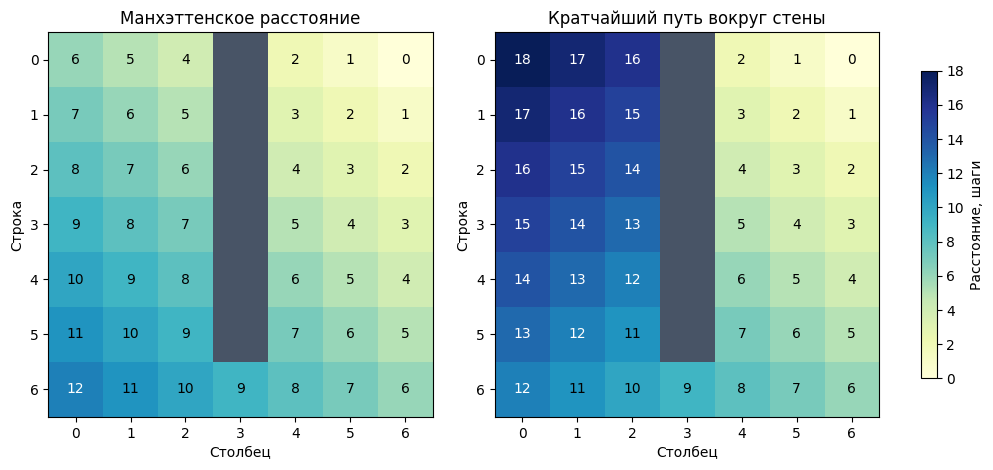

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
for ax, kind, title in zip(axes, ['manhattan', 'shortest'],
                           ['Манхэттенское расстояние', 'Кратчайший путь вокруг стены']):
    distances = np.full((SIZE, SIZE), np.nan)
    for r in range(SIZE):
        for c in range(SIZE):
            if free((r, c)):
                distances[r, c] = -potential((r, c), kind) * DISTANCE_SCALE / SHAPING_SCALE
                color = 'white' if distances[r, c] > 11 else 'black'
                ax.text(c, r, f'{distances[r, c]:.0f}', ha='center', va='center', color=color)
    ax.set_facecolor('#485466')
    plot = ax.imshow(distances, cmap='YlGnBu', vmin=0, vmax=max(DISTANCES.values()))
    ax.set(title=title, xlabel='Столбец', ylabel='Строка',
           xticks=range(SIZE), yticks=range(SIZE))
fig.colorbar(plot, ax=axes, label='Расстояние, шаги', shrink=0.8)
plt.show()


## 5. Оценка агента

Во время оценки Q-таблица не меняется. Агент выбирает действие с максимальным Q,
а при равенстве — первое. Случайность среды сохраняется.

На каждом промежуточном замере выполняю 100 эпизодов, по 25 на каждую клетку VALID.
В финальном тесте — 200 эпизодов, по 50 на каждую клетку TEST.
Оценочные seed одинаковы для всех моделей, но различаются между VALID и TEST.
При шуме 0,25 использую тот же тестовый набор.

Клетки VALID и TEST могут посещаться внутри обучающих эпизодов. Проверяется запуск из других
начальных клеток знакомой карты. Оценочные эпизоды не используются для обучения или выбора модели.

Кроме успешности, награды и длины эпизода измеряю два показателя обхода.
**Достижение прохода** равно 1, если агент хотя бы раз посетил (6, 3), иначе 0.
**Доля столкновений** — число попыток войти во внутреннюю стену, делённое на длину эпизода.
Сначала считаю эту долю для каждого эпизода, затем усредняю. Так длина эпизода не увеличивает
метрику сама по себе. Неудачные эпизоды тоже входят во все средние.


In [ ]:
def choose_action(q, state, mode, rng):
    if mode == 'random':
        return int(rng.integers(4))
    if mode == 'route':
        r, col = divmod(state, SIZE)
        if col <= 2 and r < 6:
            return 2
        if col < 6:
            return 1
        return 0
    return int(np.argmax(q[state]))


def evaluate(q, starts, episodes=VALID_EPISODES, slip=SLIP,
             mode='agent', seed_base=VALID_SEED):
    env = GridWorld(starts=starts, slip=slip)
    records = []
    for i in range(episodes):
        start = starts[i % len(starts)]
        state, _ = env.reset(seed=seed_base + i, options={'start': start})
        rng = np.random.default_rng(seed_base + 100_000 + i)
        total, collisions, wall_hits = 0.0, 0, 0
        reached = start == PASSAGE
        for t in range(1, MAX_STEPS + 1):
            action = choose_action(q, state, mode, rng)
            state, _, terminated, truncated, info = env.step(action)
            reached = reached or info['pos'] == PASSAGE
            total += info['base']
            collisions += int(info['collision'])
            wall_hits += int(info['wall_hit'])
            if terminated or truncated:
                break
        records.append([int(terminated), total, t, collisions, wall_hits,
                        int(reached), wall_hits / t])
    return np.array(records, dtype=float)


def show_table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(map(str, row)) + ' |')
    display(Markdown('\n'.join(lines)))


def avg_sd(values, digits=3):
    return f'{np.mean(values):.{digits}f} ± {np.std(values, ddof=1):.{digits}f}'

# Политика достигает прохода, затем упирается в нижнюю границу.
q_check = np.zeros((SIZE * SIZE, 4))
q_check[:, 2] = 1
q_check[6 * SIZE + 2] = [0, 1, 0, 0]
record = evaluate(q_check, [(1, 2)], episodes=1, slip=0)[0]
assert record[REACHED] == 1 and record[SUCCESS] == 0

# Постоянные попытки войти в стену дают долю столкновений 1.
q_check = np.zeros((SIZE * SIZE, 4))
q_check[:, 1] = 1
record = evaluate(q_check, [(0, 2)], episodes=1, slip=0)[0]
assert record[REACHED] == 0 and record[WALL_RATE] == 1
print('Проверки метрик прохода и столкновений пройдены.')


Проверки метрик прохода и столкновений пройдены.


## 6. Q-learning

Для этой среды достаточно таблицы из 49 строк и четырёх столбцов.
Начальные Q равны нулю. После каждого действия обновляю значение Q:

Q(s, a) ← Q(s, a) + alpha × (y − Q(s, a)).

Здесь s — текущая клетка, a — выбранное действие, а y — целевое значение.
Если агент достиг цели, y равно полученной награде r.
В остальных случаях, включая усечение, y = r + gamma × максимальное Q в следующей клетке.

Использую alpha = 0,18 и gamma = 0,99. Alpha задаёт размер обновления,
а gamma уменьшает вес будущих наград.
Первые 56 000 шагов ε линейно уменьшается с 1 до 0,05, затем остаётся равным 0,05.
При обучении действия с одинаковым максимальным Q выбираются случайно.
Каждый запуск получает ровно 80 000 обучающих переходов.
Оценка выполняется в отдельной среде и в этот бюджет не входит.


In [ ]:
def td_target(reward, next_values, terminated):
    if terminated:
        return reward
    return reward + GAMMA * np.max(next_values)


assert td_target(1.0, np.ones(4), True) == 1.0
assert np.isclose(td_target(-0.01, np.ones(4), False), -0.01 + GAMMA)


def train(seed, reward_kind):
    rng = np.random.default_rng(seed + 100_000)
    env = GridWorld(reward_kind=reward_kind)
    q = np.zeros((SIZE * SIZE, 4))
    state, _ = env.reset(seed=seed)
    curve = [evaluate(q, VALID).mean(axis=0)]
    snapshots = {}
    checkpoints = set(CHECKPOINTS[1:])

    for step in range(1, BUDGET + 1):
        progress = min(1, (step - 1) / (0.7 * BUDGET))
        epsilon = 1 - 0.95 * progress
        if rng.random() < epsilon:
            action = int(rng.integers(4))
        else:
            best = np.flatnonzero(q[state] == q[state].max())
            action = int(rng.choice(best))

        next_state, reward, terminated, truncated, _ = env.step(action)
        target = td_target(reward, q[next_state], terminated)
        q[state, action] += ALPHA * (target - q[state, action])
        if terminated or truncated:
            state, _ = env.reset()
        else:
            state = next_state

        if step in checkpoints:
            curve.append(evaluate(q, VALID).mean(axis=0))
        if step in (SNAPSHOT_STEP, BUDGET):
            snapshots[step] = q.copy()

    return q, np.array(curve), snapshots


## 7. Обучение

Обучаю десять моделей для каждого условия. Для рисунков сохраняю политики с seed 11
на 10 000 и 80 000 шагах. Финальное тестирование выполняю после обучения всех моделей.


In [ ]:
started = time.perf_counter()
curves, models, snapshots = {}, {}, {}
for name, kind in CONDITIONS.items():
    curves[name], models[name] = [], []
    for seed in SEEDS:
        q, curve, saved = train(seed, kind)
        curves[name].append(curve)
        models[name].append(q)
        if seed == SEEDS[0]:
            snapshots[name] = saved
    curves[name] = np.array(curves[name])
    print(f'{name}: завершено {len(SEEDS)} обучений')

test_records, hard_records = {}, {}
for name in CONDITIONS:
    test_records[name], hard_records[name] = [], []
    for q in models[name]:
        test_records[name].append(evaluate(q, TEST, TEST_EPISODES, seed_base=TEST_SEED))
        hard_records[name].append(evaluate(q, TEST, TEST_EPISODES, slip=0.25,
                                          seed_base=TEST_SEED))
    test_records[name] = np.array(test_records[name])
    hard_records[name] = np.array(hard_records[name])

elapsed = time.perf_counter() - started
print(f'Обучение и оценка завершены за {elapsed:.1f} с на этой машине.')
print('Обучающих переходов на условие:', len(SEEDS) * BUDGET)
print('Проверочных эпизодов на одну модель:', len(CHECKPOINTS) * VALID_EPISODES)
print('Тестовых эпизодов на одну модель:', TEST_EPISODES, 'при каждом уровне шума')



Обычная: завершено 10 обучений
Манхэттен: завершено 10 обучений
Кратчайший путь: завершено 10 обучений
Путь (норм.): завершено 10 обучений
Обучение и оценка завершены за 30.2 с на этой машине.
Обучающих переходов на условие: 800000
Проверочных эпизодов на одну модель: 3300
Тестовых эпизодов на одну модель: 200 при каждом уровне шума


## 8. Кривые обучения

Линии показывают среднее по десяти seed, полосы — ± одно стандартное отклонение (SD).
Для долей полоса ограничена диапазоном [0, 1].
На первых 20 000 шагах замеры идут каждую 1 000 шагов, далее — каждые 5 000.
Достижение прохода помогает понять, на каком этапе агенту трудно дойти до цели.


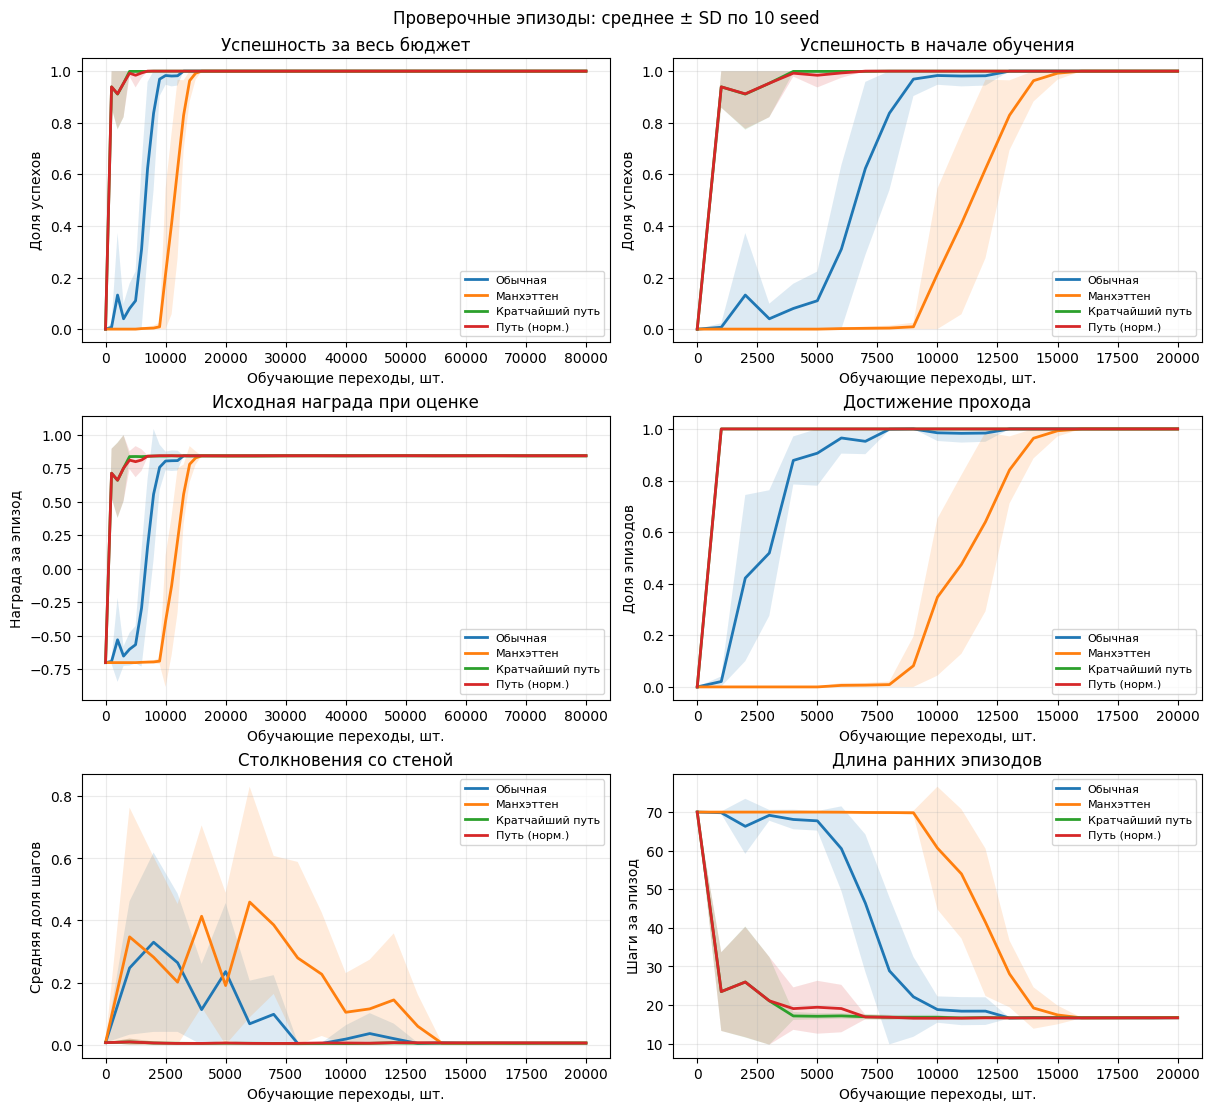

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)
settings = [(axes[0, 0], SUCCESS, BUDGET, 'Успешность за весь бюджет', 'Доля успехов'),
            (axes[0, 1], SUCCESS, EARLY_STEPS, 'Успешность в начале обучения', 'Доля успехов'),
            (axes[1, 0], RETURN, BUDGET, 'Исходная награда при оценке', 'Награда за эпизод'),
            (axes[1, 1], REACHED, EARLY_STEPS, 'Достижение прохода', 'Доля эпизодов'),
            (axes[2, 0], WALL_RATE, EARLY_STEPS, 'Столкновения со стеной', 'Средняя доля шагов'),
            (axes[2, 1], LENGTH, EARLY_STEPS, 'Длина ранних эпизодов', 'Шаги за эпизод')]
for ax, metric, end, title, ylabel in settings:
    mask = CHECKPOINTS <= end
    for name in CONDITIONS:
        values = curves[name][:, mask, metric]
        mean = values.mean(axis=0)
        sd = values.std(axis=0, ddof=1)
        lower, upper = mean - sd, mean + sd
        if metric in (SUCCESS, REACHED, WALL_RATE):
            lower, upper = np.clip(lower, 0, 1), np.clip(upper, 0, 1)
        ax.plot(CHECKPOINTS[mask], mean, label=name, linewidth=2)
        ax.fill_between(CHECKPOINTS[mask], lower, upper, alpha=0.15)
    ax.set(title=title, xlabel='Обучающие переходы, шт.', ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle('Проверочные эпизоды: среднее ± SD по 10 seed')
plt.show()


## 9. Сравнение скорости обучения

Для каждого seed считаю площадь методом трапеций и делю её на длительность периода.
Так учитываются и неравномерные интервалы между замерами.

Площадь между двумя соседними замерами = число шагов между ними × (успешность в первом замере + успешность во втором замере) / 2.

AULC = сумма этих площадей / число шагов в рассматриваемом периоде.

Успешность здесь записана долей от 0 до 1. Для полной AULC делю площадь на 80 000,
для ранней — на 20 000.

В таблице приведены среднее ± SD по десяти обучениям.
Для достижения прохода и доли столкновений также считаю среднее по времени первых 20 000 шагов.
Более высокая доля достижения прохода и меньшая доля столкновений указывают на более уверенный обход.

Парные разницы рассчитаны между запусками с одинаковым seed.
Для 95% bootstrap-интервала 10 000 раз выбираю с возвращением десять пар и считаю их среднюю разницу.
Интервал отражает разброс обучения при фиксированном наборе оценочных эпизодов.


In [ ]:
def time_average(values, times):
    widths = np.diff(times)
    trapezoids = (values[..., :-1] + values[..., 1:]) * 0.5 * widths
    return trapezoids.sum(axis=-1) / (times[-1] - times[0])


def paired_interval(differences):
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    samples = rng.choice(differences, size=(10_000, len(differences)), replace=True)
    return np.percentile(samples.mean(axis=1), [2.5, 97.5])


# Проверка интегрирования, включая неравномерные интервалы.
assert np.isclose(time_average(np.ones(3), np.array([0, 2, 5])), 1)
assert np.isclose(time_average(np.array([0, 0.4, 1]), np.array([0, 2, 5])), 0.5)
early_mask = CHECKPOINTS <= EARLY_STEPS
auc, early_auc, early_passage, early_wall = {}, {}, {}, {}
for name in CONDITIONS:
    auc[name] = time_average(curves[name][:, :, SUCCESS], CHECKPOINTS)
    early_auc[name] = time_average(curves[name][:, early_mask, SUCCESS], CHECKPOINTS[early_mask])
    early_passage[name] = time_average(curves[name][:, early_mask, REACHED], CHECKPOINTS[early_mask])
    early_wall[name] = time_average(curves[name][:, early_mask, WALL_RATE], CHECKPOINTS[early_mask])
show_table(['Условие', 'AULC 0–80 тыс.', 'AULC 0–20 тыс.', 'Проход, ранняя доля эпизодов', 'Стена, ранняя доля шагов'],
           [[name, avg_sd(auc[name]), avg_sd(early_auc[name]), avg_sd(early_passage[name]), avg_sd(early_wall[name])]
            for name in CONDITIONS])

comparisons = [('Манхэттен', 'Обычная'), ('Путь (норм.)', 'Манхэттен'),
               ('Путь (норм.)', 'Кратчайший путь')]
rows = []
for left, right in comparisons:
    for period, values in [('0–80 тыс.', auc), ('0–20 тыс.', early_auc)]:
        difference = values[left] - values[right]
        low, high = paired_interval(difference)
        rows.append([f'{left} − {right}', period, f'{difference.mean():+.5f}',
                     f'[{low:+.5f}; {high:+.5f}]', f'{np.sum(difference > 0)}/{len(SEEDS)}'])
show_table(['Разность условий', 'Период', 'Средняя ΔAULC', '95% bootstrap-интервал',
            'Пар с Δ > 0'], rows)
show_table(['Seed', 'Обычная AULC', 'Манхэттен AULC', 'Кратчайший путь AULC', 'Путь (норм.) AULC'],
           [[seed] + [f'{auc[name][i]:.3f}' for name in CONDITIONS]
            for i, seed in enumerate(SEEDS)])


| Условие | AULC 0–80 тыс. | AULC 0–20 тыс. | Проход, ранняя доля эпизодов | Стена, ранняя доля шагов |
| --- | --- | --- | --- | --- |
| Обычная | 0.919 ± 0.009 | 0.678 ± 0.037 | 0.856 ± 0.026 | 0.074 ± 0.033 |
| Манхэттен | 0.857 ± 0.014 | 0.427 ± 0.054 | 0.443 ± 0.051 | 0.162 ± 0.060 |
| Кратчайший путь | 0.991 ± 0.004 | 0.965 ± 0.015 | 0.975 ± 0.000 | 0.005 ± 0.001 |
| Путь (норм.) | 0.991 ± 0.004 | 0.964 ± 0.017 | 0.975 ± 0.000 | 0.006 ± 0.002 |

| Разность условий | Период | Средняя ΔAULC | 95% bootstrap-интервал | Пар с Δ > 0 |
| --- | --- | --- | --- | --- |
| Манхэттен − Обычная | 0–80 тыс. | -0.06260 | [-0.07169; -0.05410] | 0/10 |
| Манхэттен − Обычная | 0–20 тыс. | -0.25040 | [-0.28675; -0.21640] | 0/10 |
| Путь (норм.) − Манхэттен | 0–80 тыс. | +0.13409 | [+0.12574; +0.14233] | 10/10 |
| Путь (норм.) − Манхэттен | 0–20 тыс. | +0.53635 | [+0.50295; +0.56930] | 10/10 |
| Путь (норм.) − Кратчайший путь | 0–80 тыс. | -0.00033 | [-0.00073; -0.00001] | 1/10 |
| Путь (норм.) − Кратчайший путь | 0–20 тыс. | -0.00130 | [-0.00290; -0.00005] | 1/10 |

| Seed | Обычная AULC | Манхэттен AULC | Кратчайший путь AULC | Путь (норм.) AULC |
| --- | --- | --- | --- | --- |
| 11 | 0.930 | 0.854 | 0.994 | 0.994 |
| 22 | 0.917 | 0.856 | 0.994 | 0.994 |
| 33 | 0.911 | 0.864 | 0.993 | 0.993 |
| 44 | 0.903 | 0.837 | 0.988 | 0.988 |
| 55 | 0.927 | 0.861 | 0.994 | 0.994 |
| 66 | 0.930 | 0.839 | 0.993 | 0.993 |
| 77 | 0.914 | 0.877 | 0.988 | 0.988 |
| 88 | 0.919 | 0.856 | 0.983 | 0.981 |
| 99 | 0.929 | 0.877 | 0.994 | 0.994 |
| 110 | 0.914 | 0.848 | 0.992 | 0.991 |

## 10. Финальное качество

Сначала усредняю 200 эпизодов каждой модели, затем считаю среднее и SD между десятью моделями.
Случайный агент и маршрут по карте проходят тот же набор эпизодов.
Маршрут знает карту заранее и служит ориентиром достижимого качества.

При шуме 0,25 сравниваю тех же агентов без дополнительного обучения.
100% означает успех во всех проверенных эпизодах. Конечный набор эпизодов не исключает редкие ошибки.


In [ ]:
final_test = {name: test_records[name].mean(axis=1) for name in CONDITIONS}
hard_test = {name: hard_records[name].mean(axis=1) for name in CONDITIONS}
baselines = {}
for name, mode in [('Случайный', 'random'), ('Маршрут по карте', 'route')]:
    baselines[name] = evaluate(None, TEST, TEST_EPISODES, mode=mode,
                               seed_base=TEST_SEED).mean(axis=0)

rows = []
for name in CONDITIONS:
    values = final_test[name]
    rows.append([name, avg_sd(100 * values[:, SUCCESS], 1), avg_sd(values[:, RETURN]),
                 avg_sd(values[:, LENGTH], 2), avg_sd(values[:, COLLISIONS], 2)])
for name, values in baselines.items():
    rows.append([name, f'{100 * values[SUCCESS]:.1f}', f'{values[RETURN]:.3f}',
                 f'{values[LENGTH]:.2f}', f'{values[COLLISIONS]:.2f}'])
show_table(['Условие', 'Успех, %', 'Исходная награда', 'Шаги / эп.', 'Все столкновения / эп.'], rows)

show_table(['Условие', 'Успех при шуме 0,25, %', 'Награда', 'Шаги / эп.'],
           [[name, avg_sd(100 * hard_test[name][:, SUCCESS], 1),
             avg_sd(hard_test[name][:, RETURN]), avg_sd(hard_test[name][:, LENGTH], 2)]
            for name in CONDITIONS])

rows = []
for name in CONDITIONS:
    for j, start in enumerate(TEST):
        # Порядок эпизодов в evaluate циклически проходит по TEST.
        per_model = test_records[name][:, j::len(TEST), :].mean(axis=1)
        rows.append([name, str(start), avg_sd(100 * per_model[:, SUCCESS], 1),
                     avg_sd(per_model[:, LENGTH], 2), DISTANCES[start]])
show_table(['Условие', 'Старт', 'Успех, %', 'Шаги / эп.', 'Кратчайший путь без шума'], rows)


| Условие | Успех, % | Исходная награда | Шаги / эп. | Все столкновения / эп. |
| --- | --- | --- | --- | --- |
| Обычная | 100.0 ± 0.0 | 0.867 ± 0.001 | 14.28 ± 0.08 | 0.37 ± 0.05 |
| Манхэттен | 100.0 ± 0.0 | 0.867 ± 0.001 | 14.31 ± 0.06 | 0.37 ± 0.04 |
| Кратчайший путь | 100.0 ± 0.0 | 0.867 ± 0.001 | 14.30 ± 0.08 | 0.39 ± 0.04 |
| Путь (норм.) | 100.0 ± 0.0 | 0.867 ± 0.001 | 14.26 ± 0.11 | 0.37 ± 0.05 |
| Случайный | 1.5 | -0.682 | 69.73 | 16.03 |
| Маршрут по карте | 100.0 | 0.866 | 14.38 | 0.46 |

| Условие | Успех при шуме 0,25, % | Награда | Шаги / эп. |
| --- | --- | --- | --- |
| Обычная | 100.0 ± 0.0 | 0.837 ± 0.002 | 17.30 ± 0.23 |
| Манхэттен | 100.0 ± 0.0 | 0.836 ± 0.002 | 17.36 ± 0.18 |
| Кратчайший путь | 100.0 ± 0.0 | 0.836 ± 0.002 | 17.35 ± 0.21 |
| Путь (норм.) | 100.0 ± 0.0 | 0.837 ± 0.003 | 17.26 ± 0.28 |

| Условие | Старт | Успех, % | Шаги / эп. | Кратчайший путь без шума |
| --- | --- | --- | --- | --- |
| Обычная | (1, 2) | 100.0 ± 0.0 | 17.05 ± 0.06 | 15 |
| Обычная | (4, 2) | 100.0 ± 0.0 | 13.77 ± 0.12 | 12 |
| Обычная | (5, 0) | 100.0 ± 0.0 | 14.36 ± 0.09 | 13 |
| Обычная | (5, 2) | 100.0 ± 0.0 | 11.96 ± 0.06 | 11 |
| Манхэттен | (1, 2) | 100.0 ± 0.0 | 17.06 ± 0.04 | 15 |
| Манхэттен | (4, 2) | 100.0 ± 0.0 | 13.81 ± 0.09 | 12 |
| Манхэттен | (5, 0) | 100.0 ± 0.0 | 14.40 ± 0.07 | 13 |
| Манхэттен | (5, 2) | 100.0 ± 0.0 | 11.97 ± 0.05 | 11 |
| Кратчайший путь | (1, 2) | 100.0 ± 0.0 | 17.07 ± 0.05 | 15 |
| Кратчайший путь | (4, 2) | 100.0 ± 0.0 | 13.80 ± 0.10 | 12 |
| Кратчайший путь | (5, 0) | 100.0 ± 0.0 | 14.36 ± 0.13 | 13 |
| Кратчайший путь | (5, 2) | 100.0 ± 0.0 | 11.97 ± 0.06 | 11 |
| Путь (норм.) | (1, 2) | 100.0 ± 0.0 | 17.05 ± 0.07 | 15 |
| Путь (норм.) | (4, 2) | 100.0 ± 0.0 | 13.72 ± 0.14 | 12 |
| Путь (норм.) | (5, 0) | 100.0 ± 0.0 | 14.34 ± 0.17 | 13 |
| Путь (норм.) | (5, 2) | 100.0 ± 0.0 | 11.93 ± 0.08 | 11 |

## 11. Траектории

Показываю политики с seed 11 из клетки (1, 2). Шум отключён, чтобы видеть выбранный маршрут.
В заголовках указаны результат и длина эпизода. Повторные посещения клетки накладываются
на рисунке, поэтому в таблице также указано число уникальных клеток и столкновений.


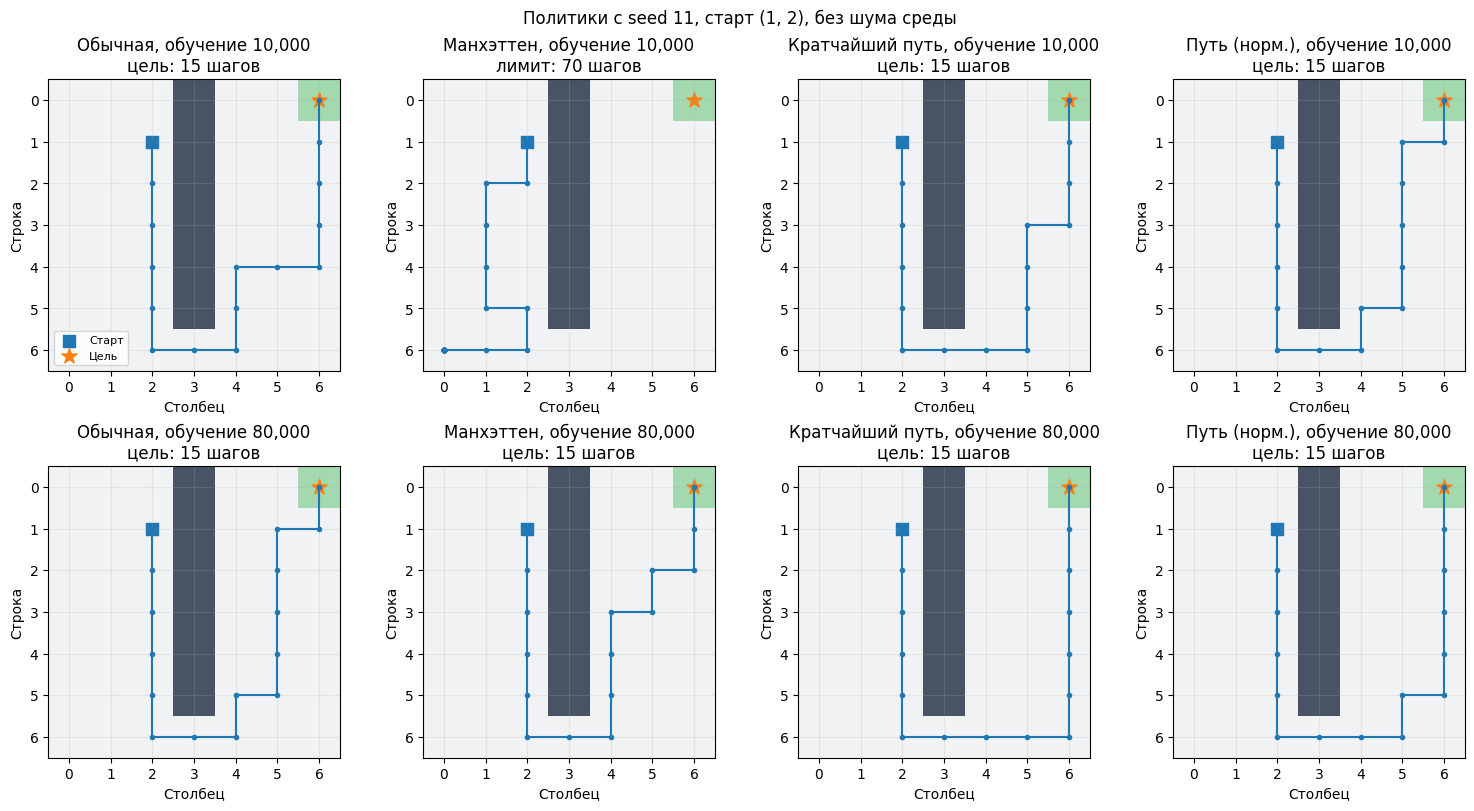

| Условие | Шаг обучения | Исход | Длина | Уникальные клетки | Столкновения |
| --- | --- | --- | --- | --- | --- |
| Обычная | 10000 | цель | 15 | 16 | 0 |
| Манхэттен | 10000 | лимит | 70 | 10 | 61 |
| Кратчайший путь | 10000 | цель | 15 | 16 | 0 |
| Путь (норм.) | 10000 | цель | 15 | 16 | 0 |
| Обычная | 80000 | цель | 15 | 16 | 0 |
| Манхэттен | 80000 | цель | 15 | 16 | 0 |
| Кратчайший путь | 80000 | цель | 15 | 16 | 0 |
| Путь (норм.) | 80000 | цель | 15 | 16 | 0 |

In [ ]:
def rollout(q, start=(1, 2)):
    env = GridWorld(slip=0)
    state, _ = env.reset(seed=123, options={'start': start})
    path = [start]
    collisions = 0
    for _ in range(MAX_STEPS):
        state, _, terminated, truncated, info = env.step(int(np.argmax(q[state])))
        path.append(env.pos)
        collisions += int(info['collision'])
        if terminated or truncated:
            break
    return path, terminated, collisions


board = np.zeros((SIZE, SIZE))
for r, c in WALLS:
    board[r, c] = 1
board[GOAL] = 2
cmap = matplotlib.colors.ListedColormap(['#f0f2f4', '#485466', '#a3d9af'])
fig, axes = plt.subplots(2, 4, figsize=(15, 8), constrained_layout=True)
route_rows = []
for i, step in enumerate([SNAPSHOT_STEP, BUDGET]):
    for j, name in enumerate(CONDITIONS):
        ax = axes[i, j]
        path, success, collisions = rollout(snapshots[name][step])
        ax.imshow(board, cmap=cmap, vmin=0, vmax=2)
        ax.plot([p[1] for p in path], [p[0] for p in path], '-o', markersize=3)
        ax.scatter(path[0][1], path[0][0], marker='s', s=70, label='Старт')
        ax.scatter(GOAL[1], GOAL[0], marker='*', s=130, label='Цель')
        status = 'цель' if success else 'лимит'
        ax.set(title=f'{name}, обучение {step:,}\n{status}: {len(path) - 1} шагов',
               xlabel='Столбец', ylabel='Строка', xticks=range(SIZE), yticks=range(SIZE))
        ax.grid(alpha=0.2)
        route_rows.append([name, step, status, len(path) - 1, len(set(path)), collisions])
axes[0, 0].legend(loc='lower left', fontsize=8)
fig.suptitle('Политики с seed 11, старт (1, 2), без шума среды')
plt.show()
show_table(['Условие', 'Шаг обучения', 'Исход', 'Длина', 'Уникальные клетки', 'Столкновения'], route_rows)


## 12. Выводы

Гипотеза не подтвердилась. Я ожидал, что манхэттенская подсказка поможет агенту быстрее научиться доходить до цели на первых 20 000 шагах. За этот период AULC с подсказкой составила 0,427, а с обычной наградой — 0,678. Средняя парная разница равна −0,250 и отрицательна во всех десяти парах seed. Значит, на этой карте и при выбранных параметрах подсказка замедлила обучение в начале.

За весь бюджет 80 000 шагов AULC с подсказкой тоже ниже: 0,857 против 0,919. При этом к концу обучения оба условия достигают 100% успешности на тесте.

**Контроль масштаба.** У манхэттенского и нормированного потенциала по пути одинаковый диапазон [−0,7; 0].
При этом нормированный вариант даёт AULC 0,991. Средняя парная разница с манхэттенским равна +0,134,
её bootstrap-интервал лежит выше нуля. Два масштаба кратчайшего пути дают близкую AULC,
которая округляется до 0,991. Значит, широкий диапазон потенциала сам по себе не объясняет
преимущество подсказки по допустимому пути.

**Достижение прохода.** Средняя по времени раннего обучения доля эпизодов с достижением прохода
равна 0,443 для манхэттенской подсказки, 0,856 для обычной награды и 0,975 для нормированного пути.
Доли столкновений со стеной на шаг равны 0,162, 0,074 и 0,006 соответственно.
Это согласуется с тем, что манхэттенская подсказка затрудняет освоение обхода.
Подсказка по пути направляет к проходу, даже когда нужно удаляться от цели.

**Пример ошибки.** После 10 000 шагов агент с манхэттенской наградой и seed 11 из (1, 2)
доходит до нижнего ряда, поворачивает влево и упирается в границу в (6, 0).
В этом эпизоде ошибка возникает ещё до пересечения прохода.
По завершении обучения все четыре показанные политики достигают цели без шума за 15 шагов,
что совпадает с кратчайшим расстоянием из этого старта.

**Итоговое качество.** Все условия дают 100% успехов на тесте, случайный агент — 1,5%,
маршрут с известной картой — 100%. При шуме 0,25 успешность обученных агентов тоже равна 100%,
а средняя длина эпизода увеличивается примерно с 14,3 до 17,3 шага.
Различие условий в этом опыте проявляется прежде всего в скорости обучения.

Потенциальная награда с тем же γ и нулём в цели сохраняет оптимальную политику дисконтированной задачи.
Это свойство не определяет скорость обучения. При табличном Q-learning такая награда также
связана со сдвигом начальных Q-значений. Поэтому геометрия подсказки и начальные оценки действий
могут вместе влиять на результат.

Для маленькой известной карты ручной маршрут уже решает задачу. Я использовал RL, чтобы проверить,
как агент осваивает поведение по наградам. В этом опыте подсказка оказалась полезной,
когда учитывала допустимый путь вокруг препятствия.


## 13. Ограничения

Я проверил одну карту и фиксированные настройки Q-learning. Все оценочные старты находятся
на знакомой карте, а их клетки могут посещаться при обучении.

Общий диапазон потенциалов не делает распределение наград одинаковым. У подсказок различаются
направление и локальные перепады. Кратчайшее расстояние также использует знание карты.

Оценочные seed общие для моделей. Bootstrap учитывает разброс между обучениями, но не всю
неопределённость оценки. Достижение прохода показывает, где возникла трудность, однако само по себе
не доказывает её причину.

Следующим шагом я бы проверил те же условия на нескольких заранее выбранных картах и новых seed оценки.


## 14. Воспроизводимость

Параметры и seed указаны в разделе 2. Там же находится команда установки библиотек.
Ниже сохранён полный список пакетов текущего окружения. Для повторения нужно выполнить
все ячейки по порядку в Jupyter или Colab.


In [ ]:
freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
print('Основные зависимости:')
for line in freeze.splitlines():
    if line.lower().startswith(('gymnasium==', 'numpy==', 'matplotlib==')):
        print(line)
display(HTML('<details><summary>Полный pip freeze текущего запуска</summary><pre>'
             + html.escape(freeze) + '</pre></details>'))


Основные зависимости:
gymnasium==1.4.0
matplotlib==3.10.8
numpy==2.3.5
